In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

In [7]:
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
df = pd.read_csv("../data/Crop_recommendation.csv")
X = df[FEATURES]
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(1760, 7) (440, 7)


In [9]:
tree=DecisionTreeClassifier(random_state=42)
tree.fit(X_train,y_train)
tree_pred=tree.predict(X_test)
print("one tree:",accuracy_score(y_test,tree_pred))
#this is single decision tree training

one tree: 0.9795454545454545


In [18]:
results=[]
for n in [1,10,50,100,200,300]:
    forest=RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )
    forest.fit(X_train,y_train)
    train_pred=forest.predict(X_train)
    test_pred=forest.predict(X_test)
    train_acc=accuracy_score(y_train,train_pred)
    test_acc=accuracy_score(y_test,test_pred)
    results.append({
        "no.of trees":n,
        "train accuracy":train_acc,
        "test accuracy":test_acc
    })

df_results=pd.DataFrame(results)
print(df_results)
#accuracy improves when no.of trees are increased
#after 50 trees adding more trees stopped making meaningful difference
#random forest is more stable than one individual tree
#yes there is a differnece and it is overfitting the stubborn train acc as 1 signifies overfitting even though test is almost 99percent
#single tree is prone to high variance and error

   no.of trees  train accuracy  test accuracy
0            1        0.985227       0.959091
1           10        1.000000       0.993182
2           50        1.000000       0.995455
3          100        1.000000       0.995455
4          200        1.000000       0.995455
5          300        1.000000       0.993182


In [19]:
param_grid={
    "n_estimators":[100,200,300],
    "max_depth":[None,10,20]
}
grid=GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    n_jobs=-1
)
grid.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'n_estimators': [100, 200, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informati

In [20]:
best_rf=grid.best_estimator_
print("Best parameters:",grid.best_params_)
print("Best CV score:",grid.best_score_)
rf_pred=best_rf.predict(X_test)
print("test accuracy:",accuracy_score(y_test,rf_pred))
#cv score--cross validation score 3,3 possible values n_est,max_depth--3*3=9*5=45 model fits-5 fold cv

Best parameters: {'max_depth': None, 'n_estimators': 300}
Best CV score: 0.9948863636363636
test accuracy: 0.9931818181818182


Text(0, 0.5, 'Features')

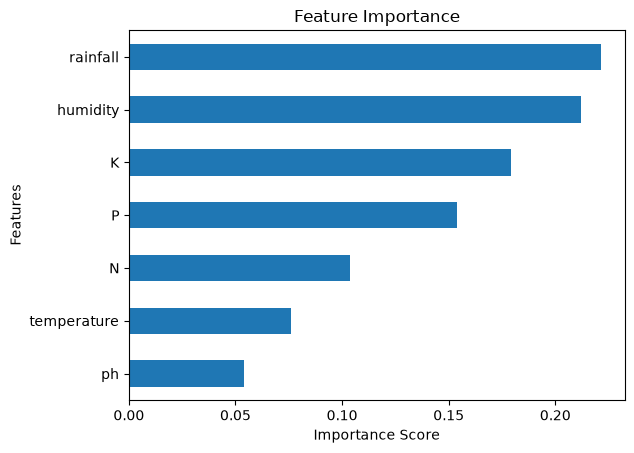

In [22]:
importance=pd.Series(
    best_rf.feature_importances_,
    index=FEATURES
).sort_values()
importance.plot(kind="barh")
plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
#highest importance---rainfall
#lowest importance---ph
#The ranking agrees with agricultural reasoning.The features rainfall,humidity are scientifically know to be critical determinants for crop growth

In [23]:
import os
print("Current folder:", os.getcwd())
print("Files in this folder:", os.listdir())

Current folder: C:\Users\K.Spoorthi\OneDrive\Desktop\crop_recommendation_role_c\notebooks
Files in this folder: ['.ipynb_checkpoints', '03_rf_tuning_saving.ipynb']


In [24]:
import joblib
import os

os.makedirs("../backend", exist_ok=True)

joblib.dump(best_rf, "../backend/crop_model.pkl")

print("Model saved!")
print("File exists:", os.path.exists("../backend/crop_model.pkl"))


Model saved!
File exists: True
